# Ejercicio 3 — Construcción de la matriz de proyección binaria

**Etiqueta de uso de IA:** *Sin IA*.

Hasta ahora simulamos un rayo por vez. Acá reunimos las máscaras de muchos rayos en una
única **matriz de proyección** $A$: para cada rayo $r$ vectorizamos su máscara $M_r$ por
filas y usamos el vector resultante como la fila $a_r^{T}$ de $A$. Si generamos $m$ rayos
sobre una imagen de $n\times n$ píxeles, entonces $A \in \mathbb{R}^{m\times n^2}$ y todas
las mediciones se obtienen de una sola vez con el producto matriz–vector

$$b = A\,x .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)

## a) y b) `matriz_proyeccion(n, direcciones)`

Para cada dirección $(\alpha,\beta)$ recorremos todos los valores posibles de
$s = \alpha i + \beta j$ con $0 \le i, j \le n-1$, los ordenamos de menor a mayor, armamos
la máscara de cada uno y agregamos su versión vectorizada como fila de $A$. La función
devuelve además la lista de pares $((\alpha,\beta), s)$ asociados a cada fila, en el mismo
orden en que se recibieron las direcciones.

Usamos `np.unique`, que además de eliminar repetidos **devuelve los valores ordenados de
menor a mayor**, que es exactamente lo que pide la consigna.

In [2]:
def matriz_proyeccion(n, direcciones):
    # Devuelve:
    #   A    : matriz (m x n^2), una fila por rayo
    #   info : lista de m pares ((alpha, beta), s), en el orden de las filas de A
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)

    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # ordenados de menor a mayor
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))

    A = np.array(filas, dtype=float)
    return A, info

## c) Aplicación con $n = 8$ y direcciones $\{(1,0),(0,1)\}$

In [3]:
direcciones = [(1, 0), (0, 1)]
A, info = matriz_proyeccion(n, direcciones)

print("forma de A:", A.shape)
print("cantidad de rayos m =", A.shape[0], "   cantidad de píxeles n^2 =", A.shape[1])
print()
assert A.shape == (16, 64), "se esperaban 16 rayos y 64 columnas"
assert len(info) == 16
print("Verificado: se obtienen 16 rayos y A ∈ R^{16x64}.")
print()
print("primeras filas de info:", info[:4])
print("últimas filas de info :", info[-4:])

forma de A: (16, 64)
cantidad de rayos m = 16    cantidad de píxeles n^2 = 64

Verificado: se obtienen 16 rayos y A ∈ R^{16x64}.

primeras filas de info: [((1, 0), 0), ((1, 0), 1), ((1, 0), 2), ((1, 0), 3)]
últimas filas de info : [((0, 1), 4), ((0, 1), 5), ((0, 1), 6), ((0, 1), 7)]


In [4]:
# Las 8 primeras filas son las filas de la imagen (i = 0..7);
# las 8 siguientes, las columnas (j = 0..7).
for r in [0, 3, 8, 13]:
    d, s = info[r]
    print(f"fila r={r:2d}  dirección {d}  s={s}  ->  {A[r].astype(int)}")
    print(f"            máscara ({int(A[r].sum())} píxeles):")
    print(A[r].reshape(n, n).astype(int))
    print()

fila r= 0  dirección (1, 0)  s=0  ->  [1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
            máscara (8 píxeles):
[[1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

fila r= 3  dirección (1, 0)  s=3  ->  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
            máscara (8 píxeles):
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

fila r= 8  dirección (0, 1)  s=0  ->  [1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
            máscara (8 píxeles):
[[1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 0 

## d) ¿Qué representa una fila y qué representa una columna de $A$?

- **Una fila** $a_r^{T}$ describe **un rayo**: tiene un $1$ en la posición $k = i\,n+j$ de
  cada píxel que el rayo atraviesa (en el modelo binario, cuyo centro pertenece al rayo
  discreto) y $0$ en el resto. La medición de ese rayo es $b_r = a_r^{T}x$, o sea la suma de
  las atenuaciones de esos píxeles. Cada fila es una **ecuación** del sistema.

- **Una columna** $A_{:,k}$ describe **un píxel**: tiene un $1$ en la posición $r$ de cada
  rayo que lo atraviesa. Dicho de otro modo, indica en qué mediciones participa el píxel $k$
  y, por lo tanto, cuánta evidencia tenemos sobre él. Multiplicar $Ax$ es tomar la
  combinación lineal de las columnas con pesos $x_k$: cada píxel "reparte" su atenuación
  entre las mediciones que lo ven.

Además $A$ es **dispersa** (rala). Con $n = 8$ y direcciones $(1,0)$ y $(0,1)$, cada rayo
toca a lo sumo $8$ de los $64$ píxeles, así que a lo sumo el $1/8 = 12.5\%$ de las entradas
son no nulas. En un problema real ($128\times128$ píxeles, miles de rayos) la fracción es
muchísimo menor, y por eso conviene almacenar $A$ en formato disperso.

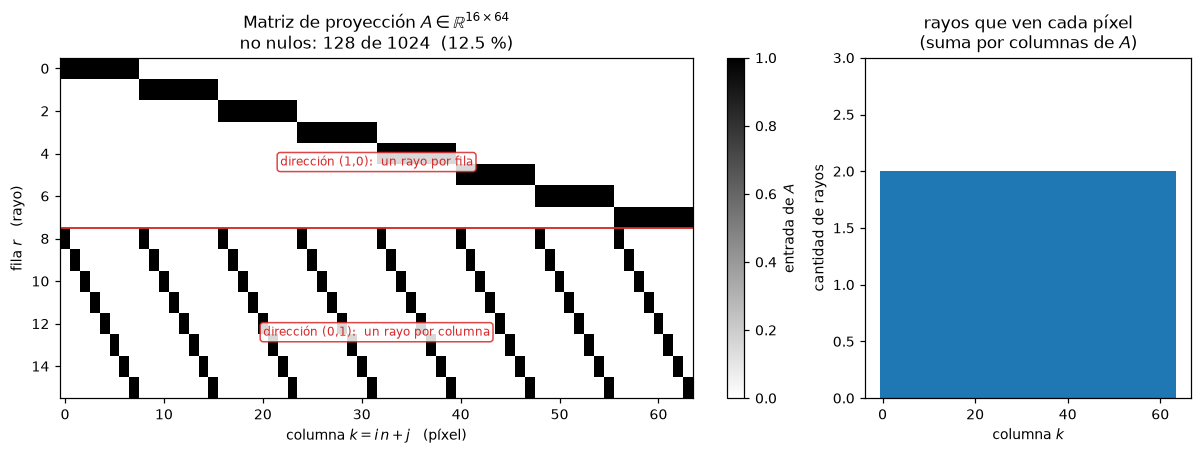

In [5]:
densidad = np.count_nonzero(A) / A.size

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2),
                         gridspec_kw={"width_ratios": [2.1, 1]})

im = axes[0].imshow(A, cmap="gray_r", aspect="auto", interpolation="nearest")
axes[0].set_title(f"Matriz de proyección $A \\in \\mathbb{{R}}^{{16 \\times 64}}$\n"
                  f"no nulos: {np.count_nonzero(A)} de {A.size}  "
                  f"({100 * densidad:.1f} %)")
axes[0].set_xlabel(r"columna $k = i\,n + j$   (píxel)")
axes[0].set_ylabel("fila $r$   (rayo)")
axes[0].axhline(7.5, color="tab:red", lw=1.2)
caja = dict(boxstyle="round,pad=0.25", fc="white", ec="tab:red", alpha=0.85)
axes[0].text(31.5, 4.4, "dirección (1,0):  un rayo por fila", color="tab:red",
             fontsize=8, ha="center", va="center", bbox=caja)
axes[0].text(31.5, 12.4, "dirección (0,1):  un rayo por columna", color="tab:red",
             fontsize=8, ha="center", va="center", bbox=caja)
fig.colorbar(im, ax=axes[0], fraction=0.025, label="entrada de $A$")

axes[1].bar(np.arange(64), A.sum(axis=0), width=1.0, color="tab:blue")
axes[1].set_title("rayos que ven cada píxel\n(suma por columnas de $A$)")
axes[1].set_xlabel(r"columna $k$")
axes[1].set_ylabel("cantidad de rayos")
axes[1].set_ylim(0, 3)

fig.tight_layout()
guardar(fig, "ejercicio_03d_matriz_A")
plt.show()

En el panel derecho se ve que **cada píxel es visto por exactamente 2 rayos**: el de su
fila y el de su columna. Con sólo $64$ incógnitas y $2$ ecuaciones "útiles" por píxel, ya se
intuye que $16$ mediciones no van a alcanzar para determinar $64$ valores; eso lo
formalizamos en el Ejercicio 4.

El patrón visible en la mitad superior de $A$ (bloques contiguos de ocho unos) corresponde a
las filas de la imagen, mientras que la mitad inferior (unos espaciados cada $8$ columnas)
corresponde a las columnas. Los ceros dominan porque cada rayo sólo toca $8$ de los $64$
píxeles.

## e) Mediciones $b = A\,x_{\text{fantoma}}$

Las primeras ocho componentes deben coincidir con las sumas por filas del fantoma
(`X_fantoma.sum(axis=1)`) y las ocho restantes, con las sumas por columnas
(`X_fantoma.sum(axis=0)`).

In [6]:
b = A @ x_fantoma

suma_filas = X_fantoma.sum(axis=1)
suma_columnas = X_fantoma.sum(axis=0)

print("b (16 componentes):")
print(np.round(b, 3))
print()
print("b[:8]                     =", np.round(b[:8], 3))
print("X_fantoma.sum(axis=1)     =", np.round(suma_filas, 3))
print("¿coinciden?", np.allclose(b[:8], suma_filas))
print()
print("b[8:]                     =", np.round(b[8:], 3))
print("X_fantoma.sum(axis=0)     =", np.round(suma_columnas, 3))
print("¿coinciden?", np.allclose(b[8:], suma_columnas))
print()
print("suma total de b:", b.sum(), " = 2 x suma del fantoma:", 2 * X_fantoma.sum())

b (16 componentes):
[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]

b[:8]                     = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
X_fantoma.sum(axis=1)     = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
¿coinciden? True

b[8:]                     = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
X_fantoma.sum(axis=0)     = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
¿coinciden? True

suma total de b: 26.200000000000003  = 2 x suma del fantoma: 26.200000000000003


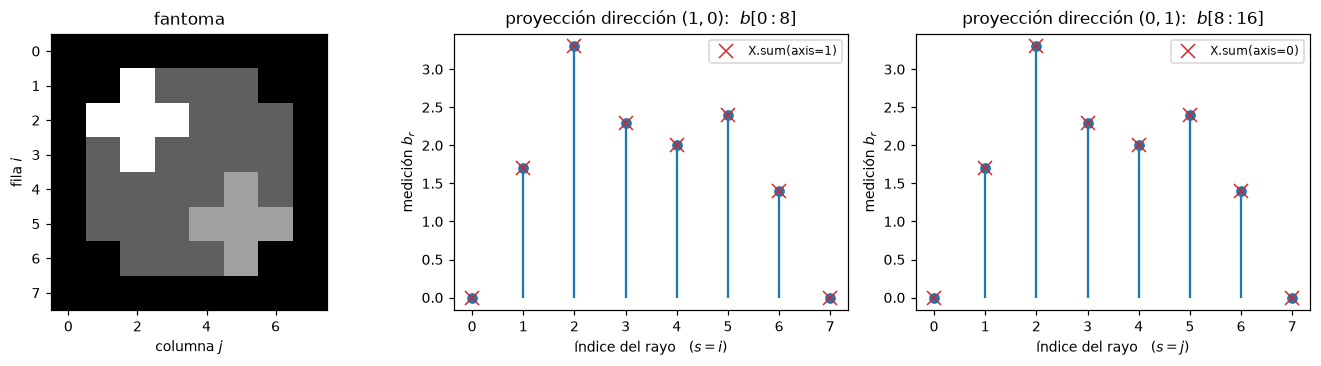

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))

axes[0].imshow(X_fantoma, cmap="gray", vmin=0, vmax=X_fantoma.max())
axes[0].set_title("fantoma")
axes[0].set_xlabel("columna $j$")
axes[0].set_ylabel("fila $i$")

axes[1].stem(np.arange(8), b[:8], basefmt=" ")
axes[1].plot(np.arange(8), suma_filas, "x", color="tab:red", ms=9,
             label="X.sum(axis=1)")
axes[1].set_title(r"proyección dirección $(1,0)$:  $b[0:8]$")
axes[1].set_xlabel("índice del rayo   ($s = i$)")
axes[1].set_ylabel("medición $b_r$")
axes[1].legend(fontsize=8)

axes[2].stem(np.arange(8), b[8:], basefmt=" ")
axes[2].plot(np.arange(8), suma_columnas, "x", color="tab:red", ms=9,
             label="X.sum(axis=0)")
axes[2].set_title(r"proyección dirección $(0,1)$:  $b[8:16]$")
axes[2].set_xlabel("índice del rayo   ($s = j$)")
axes[2].set_ylabel("medición $b_r$")
axes[2].legend(fontsize=8)

fig.tight_layout()
guardar(fig, "ejercicio_03e_proyecciones")
plt.show()

Cada bloque de $8$ mediciones es una **proyección** en el sentido del enunciado: el
conjunto de mediciones obtenido para una orientación fija, recorriendo las distintas
posiciones $s$ del detector. Vistas como señales unidimensionales, ambas proyecciones tienen
la forma esperada: valen $0$ en los extremos (las filas/columnas $0$ y $7$ del fantoma son
todas nulas) y alcanzan su máximo en el centro del objeto, donde hay más material.

Si apiláramos muchas de estas proyecciones, una por ángulo, obtendríamos el **sinograma**
$S \in \mathbb{R}^{K\times q}$ descripto en la introducción. Con sólo dos direcciones
tenemos un "sinograma" de $2$ filas.